In [1]:
import os

print(os.listdir("../data/raw"))

['.cache', 'aa_dataset-tickets-multi-lang-5-2-50-version.csv']


In [2]:
import pandas as pd

df = pd.read_csv(
    "../data/raw/aa_dataset-tickets-multi-lang-5-2-50-version.csv"
)

print(df.shape)
print(df.columns)
display(df.head())

(28587, 16)
Index(['subject', 'body', 'answer', 'type', 'queue', 'priority', 'language',
       'version', 'tag_1', 'tag_2', 'tag_3', 'tag_4', 'tag_5', 'tag_6',
       'tag_7', 'tag_8'],
      dtype='str')


,subject,body,answer,type,queue,priority,language,version,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8
0,Wesentlicher Sicherheitsvorfall,"Sehr geehrtes Support-Team,\n\nich möchte eine...",Vielen Dank für die Meldung des kritischen Sic...,Incident,Technical Support,high,de,51,Security,Outage,Disruption,Data Breach,NaN,NaN,NaN,NaN
1,Account Disruption,"Dear Customer Support Team,\n\nI am writing to...","Thank you for reaching out, <name>. We are awa...",Incident,Technical Support,high,en,51,Account,Disruption,Outage,IT,Tech Support,NaN,NaN,NaN
2,Query About Smart Home System Integration Feat...,"Dear Customer Support Team,\n\nI hope this mes...",Thank you for your inquiry. Our products suppo...,Request,Returns and Exchanges,medium,en,51,Product,Feature,Tech Support,NaN,NaN,NaN,NaN,NaN
3,Inquiry Regarding Invoice Details,"Dear Customer Support Team,\n\nI hope this mes...",We appreciate you reaching out with your billi...,Request,Billing and Payments,low,en,51,Billing,Payment,Account,Documentation,Feedback,NaN,NaN,NaN
4,Question About Marketing Agency Software Compa...,"Dear Support Team,\n\nI hope this message reac...",Thank you for your inquiry. Our product suppor...,Problem,Sales and Pre-Sales,medium,en,51,Product,Feature,Feedback,Tech Support,NaN,NaN,NaN,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 28587 entries, 0 to 28586
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   subject   24749 non-null  str  
 1   body      28587 non-null  str  
 2   answer    28580 non-null  str  
 3   type      28587 non-null  str  
 4   queue     28587 non-null  str  
 5   priority  28587 non-null  str  
 6   language  28587 non-null  str  
 7   version   28587 non-null  int64
 8   tag_1     28587 non-null  str  
 9   tag_2     28574 non-null  str  
 10  tag_3     28451 non-null  str  
 11  tag_4     25529 non-null  str  
 12  tag_5     14545 non-null  str  
 13  tag_6     5874 non-null   str  
 14  tag_7     2040 non-null   str  
 15  tag_8     565 non-null    str  
dtypes: int64(1), str(15)
memory usage: 3.5 MB


In [4]:
df.isnull().sum()

subject      3838
body            0
answer          7
type            0
queue           0
priority        0
language        0
version         0
tag_1           0
tag_2          13
tag_3         136
tag_4        3058
tag_5       14042
tag_6       22713
tag_7       26547
tag_8       28022
dtype: int64

In [5]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
subject,24749,24749,Wesentlicher Sicherheitsvorfall,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
body,28587,28587,"Sehr geehrtes Support-Team,\n\nich möchte eine...",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
answer,28580,28580,Vielen Dank für die Meldung des kritischen Sic...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,28587,4,Incident,11466,NaN,NaN,NaN,NaN,NaN,NaN,NaN
queue,28587,10,Technical Support,8362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
priority,28587,3,medium,11515,NaN,NaN,NaN,NaN,NaN,NaN,NaN
language,28587,2,en,16338,NaN,NaN,NaN,NaN,NaN,NaN,NaN
version,28587.0,NaN,NaN,NaN,278.382027,165.962935,51.0,52.0,400.0,400.0,400.0
tag_1,28587,116,Security,5880,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tag_2,28574,256,Performance,5903,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 28587
Columns: 16


In [8]:
df['language'].value_counts()

language
en    16338
de    12249
Name: count, dtype: int64

In [9]:
df['queue'].value_counts()

queue
Technical Support                  8362
Product Support                    5252
Customer Service                   4268
IT Support                         3433
Billing and Payments               2788
Returns and Exchanges              1437
Service Outages and Maintenance    1148
Sales and Pre-Sales                 918
Human Resources                     576
General Inquiry                     405
Name: count, dtype: int64

In [10]:
df['priority'].value_counts()

priority
medium    11515
high      11178
low        5894
Name: count, dtype: int64

In [11]:
df['type'].value_counts()

type
Incident    11466
Request      8187
Problem      6012
Change       2922
Name: count, dtype: int64

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

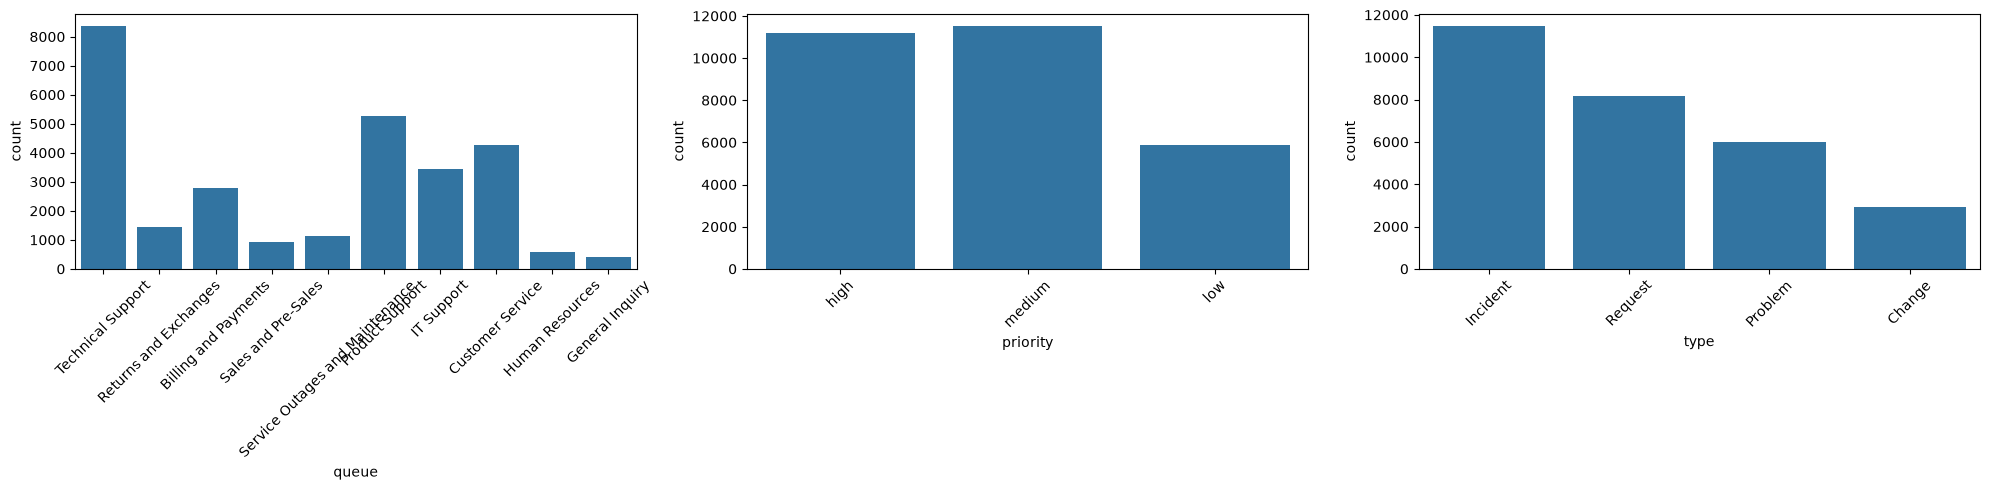

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(20,5))
sns.countplot(data=df, x= 'queue' , ax=axes[0])
sns.countplot(data=df, x= 'priority' , ax=axes[1])
sns.countplot(data=df, x= 'type' , ax=axes[2])

for ax in axes:
    ax.tick_params(axis='x' , rotation=45)

plt.tight_layout()
plt.show()

In [14]:
print("QUEUE DISTRIBUTION")
print(df['queue'].value_counts())
print("\nQUEUE PERCENTAGE")
print(df['queue'].value_counts(normalize=True) * 100)
print("PRIORITY DISTRIBUTION")
print(df['priority'].value_counts())
print("\nPRIORITY PERCENTAGE")
print(df['priority'].value_counts(normalize=True) * 100)
print("TYPE DISTRIBUTION")
print(df['type'].value_counts())
print("\nTYPE PERCENTAGE")
print(df['type'].value_counts(normalize=True) * 100)

QUEUE DISTRIBUTION
queue
Technical Support                  8362
Product Support                    5252
Customer Service                   4268
IT Support                         3433
Billing and Payments               2788
Returns and Exchanges              1437
Service Outages and Maintenance    1148
Sales and Pre-Sales                 918
Human Resources                     576
General Inquiry                     405
Name: count, dtype: int64

QUEUE PERCENTAGE
queue
Technical Support                  29.251058
Product Support                    18.371987
Customer Service                   14.929863
IT Support                         12.008955
Billing and Payments                9.752685
Returns and Exchanges               5.026760
Service Outages and Maintenance     4.015811
Sales and Pre-Sales                 3.211250
Human Resources                     2.014902
General Inquiry                     1.416728
Name: proportion, dtype: float64
PRIORITY DISTRIBUTION
priority
medium    1

In [15]:
df[['subject', 'body', 'queue', 'priority', 'type']].sample(
    5, random_state=42
)

,subject,body,queue,priority,type
9284,NaN,"Kundenservice, ich möchte einen Vorfall melden...",Technical Support,high,Incident
2647,NaN,"Sehr geehrter Kundenservice, ich möchte detail...",Technical Support,high,Request
3820,Issues with Brand Expansion,Despite enhancing ad text and boosting the bud...,IT Support,high,Incident
18831,Unusual Decline in Engagement Metrics for Camp...,noted a sudden decline in engagement metrics a...,Returns and Exchanges,high,Incident
7667,Medizinische Daten in Gesundheits-IT-Lösungen,"Sehr geehrter Kundenservice, ich möchte mich n...",Billing and Payments,low,Request


In [16]:
df['body'].str.len().describe()

count    28587.000000
mean       387.263896
std        200.129011
min          6.000000
25%        219.000000
50%        386.000000
75%        551.000000
max       1469.000000
Name: body, dtype: float64

In [17]:
df.groupby('language')['subject'].apply(
    lambda x: x.isnull().sum()
)

language
de    1231
en    2607
Name: subject, dtype: int64

In [18]:
df.groupby('language')['subject'].apply(
    lambda x: x.isnull().mean() * 100
)

language
de    10.049800
en    15.956665
Name: subject, dtype: float64

In [19]:
df_en = df[df['language'] == 'en'].copy()

print("Original dataset:", df.shape)
print("English dataset:", df_en.shape)

Original dataset: (28587, 16)
English dataset: (16338, 16)


In [20]:
df_en[['subject', 'body', 'queue', 'priority', 'type']].sample(
    5, random_state=42
)

,subject,body,queue,priority,type
25705,Query on Data Analytics Tools for Investment O...,"Dear Customer Support, I am inquiring about th...",IT Support,low,Request
17458,Problems with Connection,Customers are facing occasional connectivity p...,IT Support,medium,Problem
22023,NaN,"Hello Customer Support, I am inquiring about o...",Billing and Payments,medium,Request
25800,Found Issues with Secure Data Access in Hospit...,We have identified secure data access issues w...,Technical Support,medium,Problem
25239,NaN,Could you offer assistance on securing medical...,IT Support,medium,Request


In [21]:
for col in ['queue', 'priority', 'type']:
    print(f"\n{col.upper()} DISTRIBUTION")
    print(df_en[col].value_counts())

    print("\nPercentage:")
    print(df_en[col].value_counts(normalize=True) * 100)


QUEUE DISTRIBUTION
queue
Technical Support                  4737
Product Support                    3073
Customer Service                   2410
IT Support                         1942
Billing and Payments               1595
Returns and Exchanges               820
Service Outages and Maintenance     664
Sales and Pre-Sales                 513
Human Resources                     348
General Inquiry                     236
Name: count, dtype: int64

Percentage:
queue
Technical Support                  28.993757
Product Support                    18.808912
Customer Service                   14.750888
IT Support                         11.886400
Billing and Payments                9.762517
Returns and Exchanges               5.018974
Service Outages and Maintenance     4.064145
Sales and Pre-Sales                 3.139919
Human Resources                     2.130004
General Inquiry                     1.444485
Name: proportion, dtype: float64

PRIORITY DISTRIBUTION
priority
medium    6618

In [22]:
df_en['body'].str.len().describe()

count    16338.000000
mean       367.887379
std        179.885725
min          6.000000
25%        214.000000
50%        377.000000
75%        533.000000
max       1147.000000
Name: body, dtype: float64

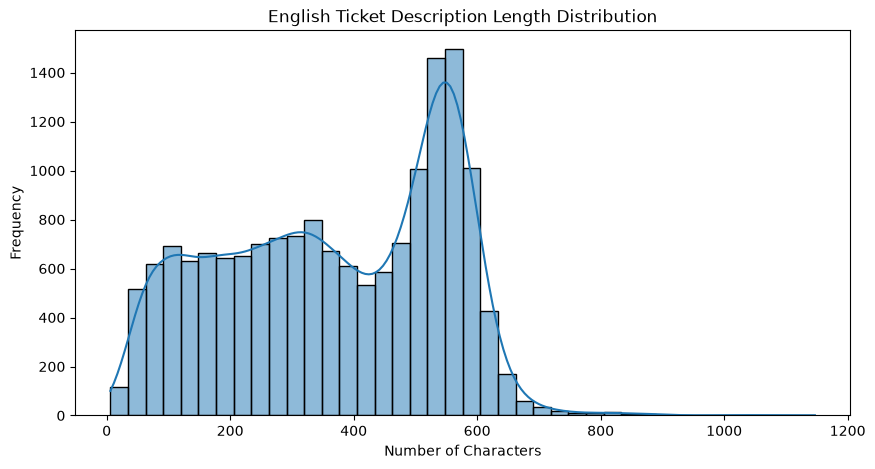

In [23]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df_en['body'].str.len(),
    bins=40,
    kde=True
)

plt.title("English Ticket Description Length Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")

plt.show()

In [24]:
print(
    "Duplicate bodies:",
    df_en['body'].duplicated().sum()
)

Duplicate bodies: 0


In [25]:
print(
    "Duplicate subject-body pairs:",
    df_en.duplicated(
        subset=['subject', 'body']
    ).sum()
)

Duplicate subject-body pairs: 0


In [26]:
for i, row in df_en.sample(
    5, random_state=42
).iterrows():

    print("SUBJECT:", row['subject'])
    print("BODY:", row['body'])
    print("QUEUE:", row['queue'])
    print("PRIORITY:", row['priority'])
    print("TYPE:", row['type'])
    print("-" * 80)

SUBJECT: Query on Data Analytics Tools for Investment Optimization
BODY: Dear Customer Support, I am inquiring about the data analytics tools that are available to assist in optimizing investment strategies. Could you provide detailed information on the types of tools that are used to make informed investment decisions? I would greatly appreciate any information provided, including relevant resources and recommendations. Thank you for your assistance, and I look forward to hearing from you soon. Please let me know if any additional information is needed.
QUEUE: IT Support
PRIORITY: low
TYPE: Request
--------------------------------------------------------------------------------
SUBJECT: Problems with Connection
BODY: Customers are facing occasional connectivity problems with the SaaS platform. This could be due to network instability or incorrect configuration. After restarting devices and reconfiguring settings, as well as checking service statuses, no solution has been found. The te

In [27]:
for queue in df_en['queue'].unique():

    print("\n" + "=" * 80)
    print("QUEUE:", queue)
    print("=" * 80)

    sample = df_en[df_en['queue'] == queue].sample(
        min(3, len(df_en[df_en['queue'] == queue])),
        random_state=42
    )

    for _, row in sample.iterrows():
        print("SUBJECT:", row['subject'])
        print("BODY:", row['body'][:300])
        print("PRIORITY:", row['priority'])
        print("TYPE:", row['type'])
        print("-" * 50)


QUEUE: Technical Support
SUBJECT: Support Needed for PostgreSQL Integration in Scalable SaaS Project Management Solution
BODY: Dear Support, I am reaching out to request detailed documentation for integrating PostgreSQL 13 into our scalable SaaS project management solution. Could you provide step-by-step instructions to configure the database connection and ensure seamless data synchronization? I would also appreciate any t
PRIORITY: high
TYPE: Request
--------------------------------------------------
SUBJECT: Timeout Issues with Project Dashboard
BODY: Customer Support reports that users frequently encounter timeouts when accessing the project management dashboard, likely due to recent spikes in database load. Restarting servers and clearing caches did not resolve the problem. The issue began after the latest update and affects multiple user accou
PRIORITY: high
TYPE: Incident
--------------------------------------------------
SUBJECT: System Timeouts During Peak Periods
BODY: Custo

In [28]:
print("Total English tickets:", len(df_en))

print(
    "Missing subjects:",
    df_en['subject'].isnull().sum()
)

print(
    "Unique subjects:",
    df_en['subject'].nunique()
)

print(
    "Unique ticket types:",
    df_en['type'].nunique()
)

Total English tickets: 16338
Missing subjects: 2607
Unique subjects: 13731
Unique ticket types: 4


In [29]:
pd.crosstab(
    df_en['queue'],
    df_en['priority']
)

priority,high,low,medium
queue,,,
Billing and Payments,483,342,770
Customer Service,452,837,1121
General Inquiry,38,129,69
Human Resources,35,171,142
IT Support,938,178,826
Product Support,899,599,1575
Returns and Exchanges,185,313,322
Sales and Pre-Sales,88,188,237
Service Outages and Maintenance,467,83,114


In [30]:
pd.crosstab(
    df_en['queue'],
    df_en['type']
)

type,Change,Incident,Problem,Request
queue,,,,
Billing and Payments,95,386,344,770
Customer Service,195,607,520,1088
General Inquiry,67,71,49,49
Human Resources,20,184,36,108
IT Support,338,689,490,425
Product Support,350,1383,666,674
Returns and Exchanges,105,319,163,233
Sales and Pre-Sales,90,103,62,258
Service Outages and Maintenance,151,369,44,100


In [31]:
queue_priority = pd.crosstab(
    df_en['queue'],
    df_en['priority'],
    normalize='index'
) * 100

display(queue_priority.round(2))

queue_type = pd.crosstab(
    df_en['queue'],
    df_en['type'],
    normalize='index'
) * 100

display(queue_type.round(2))

priority,high,low,medium
queue,,,
Billing and Payments,30.28,21.44,48.28
Customer Service,18.76,34.73,46.51
General Inquiry,16.10,54.66,29.24
Human Resources,10.06,49.14,40.80
IT Support,48.30,9.17,42.53
Product Support,29.25,19.49,51.25
Returns and Exchanges,22.56,38.17,39.27
Sales and Pre-Sales,17.15,36.65,46.20
Service Outages and Maintenance,70.33,12.50,17.17


type,Change,Incident,Problem,Request
queue,,,,
Billing and Payments,5.96,24.20,21.57,48.28
Customer Service,8.09,25.19,21.58,45.15
General Inquiry,28.39,30.08,20.76,20.76
Human Resources,5.75,52.87,10.34,31.03
IT Support,17.40,35.48,25.23,21.88
Product Support,11.39,45.00,21.67,21.93
Returns and Exchanges,12.80,38.90,19.88,28.41
Sales and Pre-Sales,17.54,20.08,12.09,50.29
Service Outages and Maintenance,22.74,55.57,6.63,15.06


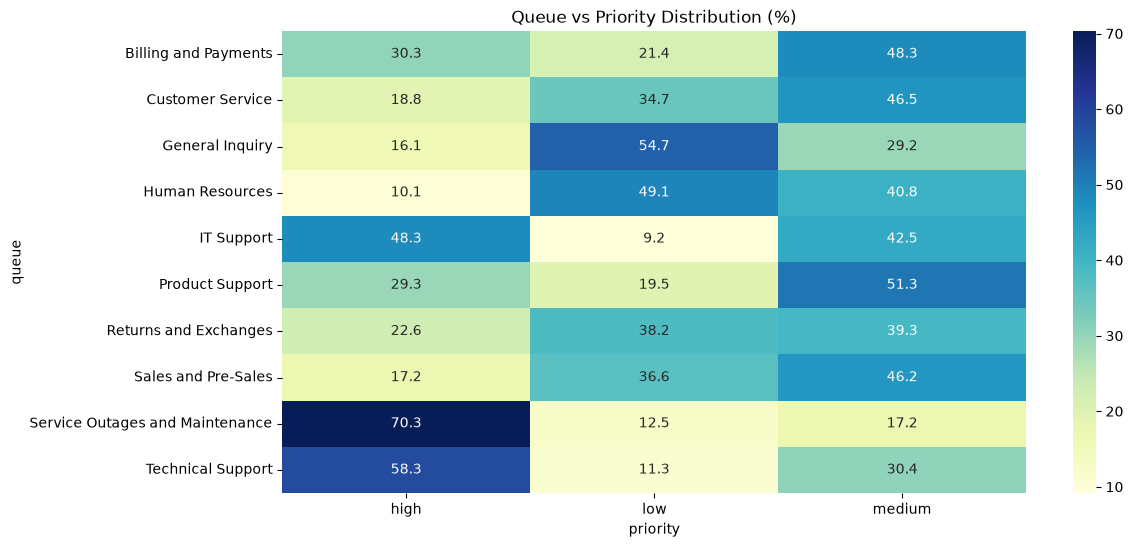

In [32]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    queue_priority,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu'
)

plt.title('Queue vs Priority Distribution (%)')
plt.show()

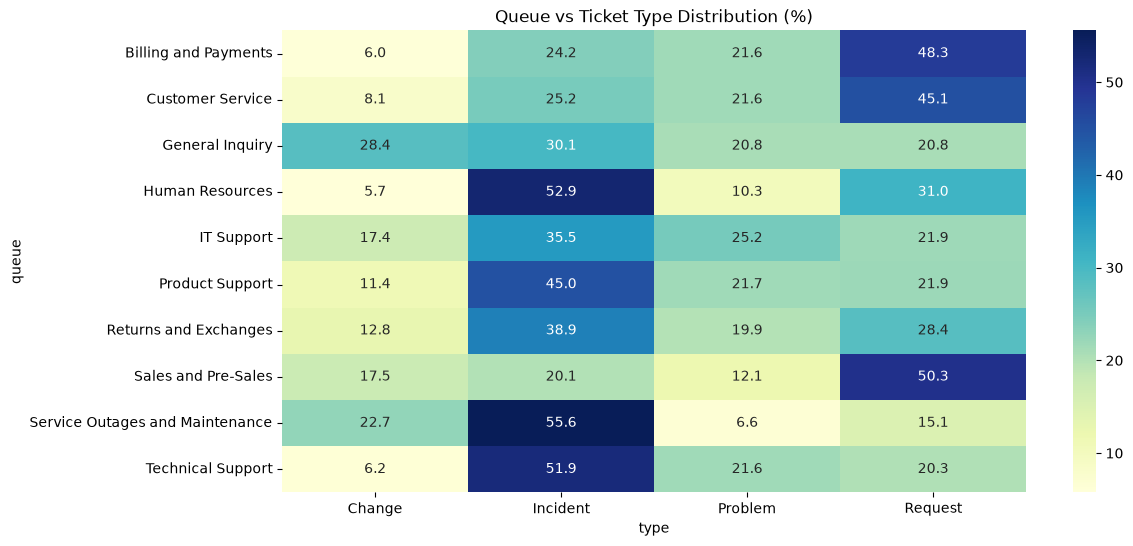

In [33]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    queue_type,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu'
)

plt.title('Queue vs Ticket Type Distribution (%)')
plt.show()

In [34]:
print("Total tickets:", len(df_en))
print("Missing subjects:", df_en['subject'].isnull().sum())
print("Unique subjects:", df_en['subject'].nunique())

Total tickets: 16338
Missing subjects: 2607
Unique subjects: 13731


In [35]:
df_model = df_en.copy()
print("original eng dataset:" , df_en.shape)
print("working eng dataset:" , df_model.shape)

original eng dataset: (16338, 16)
working eng dataset: (16338, 16)


In [36]:
df_model['subject'] = df_model['subject'].fillna('')

In [37]:
df_model['text'] = (df_model['subject']+ ' '+df_model['body'])


In [38]:
df_model[['subject' , 'body' ,'text']]

,subject,body,text
1,Account Disruption,"Dear Customer Support Team,\n\nI am writing to...","Account Disruption Dear Customer Support Team,..."
2,Query About Smart Home System Integration Feat...,"Dear Customer Support Team,\n\nI hope this mes...",Query About Smart Home System Integration Feat...
3,Inquiry Regarding Invoice Details,"Dear Customer Support Team,\n\nI hope this mes...",Inquiry Regarding Invoice Details Dear Custome...
4,Question About Marketing Agency Software Compa...,"Dear Support Team,\n\nI hope this message reac...",Question About Marketing Agency Software Compa...
5,Feature Query,"Dear Customer Support,\n\nI hope this message ...","Feature Query Dear Customer Support,\n\nI hope..."
...,...,...,...
28578,Problem with Billing Adjustment,An unexpected billing discrepancy has been not...,Problem with Billing Adjustment An unexpected ...
28580,Urgent: Incident Involving Data Breach in Medi...,"A data breach has occurred, which might be rel...",Urgent: Incident Involving Data Breach in Medi...
28582,Performance Problem with Data Analytics Tool,The data analytics tool experiences sluggish p...,Performance Problem with Data Analytics Tool T...
28585,Update Request for SaaS Platform Integration F...,Requesting an update on the integration featur...,Update Request for SaaS Platform Integration F...


In [39]:
print('missing text values' , df_model['text'].isnull().sum())
print("empty text vals" , (df_model['text'].str.strip() == '').sum())

missing text values 0
empty text vals 0


In [40]:
import re

html_count = df_model['text'].str.contains(
    r'<[^>]+>',
    regex=True
).sum()

print("Records containing HTML tags:", html_count)

url_count = df_model['text'].str.contains(
    r'https?://\S+|www\.\S+',
    regex=True
).sum()

print("Records containing URLs:", url_count)

Records containing HTML tags: 520
Records containing URLs: 0


In [41]:
html_rows = df_model[
    df_model['text'].str.contains(r'<[^>]+>', regex=True, na=False)
]

print("HTML-containing records:", len(html_rows))

for text in html_rows['text'].head(5):
    print(text)
    print("-" * 100)

print("Missing text values:", df_model['text'].isnull().sum())
print("Empty text values:", (df_model['text'].str.strip() == '').sum())

HTML-containing records: 520
Billing Discrepancies Reported by Financial Institution Dear Customer Support,<br><br>I am submitting a report concerning a critical problem within the billing system of the financial organization. The issue involves errors that are impacting several products related to investment data analytics and optimization. It appears that the problem is probably due to integration issues within the system. Our team has attempted to review invoices and reset payment gateways, but unfortunately, we have not yet found a solution.<br><br>The errors are causing incorrect billing amounts and payments, leading to considerable disruptions in business operations. We are worried that this problem may continue to affect our activities.
----------------------------------------------------------------------------------------------------
Healthcare Data Security Solutions Dear Support Team,<br>I am reaching out to inquire about healthcare data security solutions and hospital infra

In [42]:
pip install beautifulsoup4

Note: you may need to restart the kernel to use updated packages.


In [50]:
import re 
from bs4 import BeautifulSoup
def clean_text(text):
    text = text.replace(r'\n',' ')
    text = text.replace(r'\t',' ')
    text = text.replace(r'\r',' ')
    text = BeautifulSoup(text , "html.parser").get_text(separator=" ")
    text = re.sub(r'\s+' , ' ',text)
    text = text.strip()
    return text 

In [51]:
df_model['cleaned_text'] = df_model['text'].apply(clean_text)


In [52]:
html_remaining = df_model['cleaned_text'].str.contains(
    r'<[^>]+>', regex=True, na=False
).sum()

print("HTML tags remaining:", html_remaining)
print("Missing cleaned text:", df_model['cleaned_text'].isnull().sum())
print("Empty cleaned text:", (df_model['cleaned_text'].str.strip() == '').sum())

HTML tags remaining: 0
Missing cleaned text: 0
Empty cleaned text: 0


In [53]:
df_model['cleaned_text'] = df_model['cleaned_text'].str.lower()

In [54]:
pip install nltk

Note: you may need to restart the kernel to use updated packages.


In [55]:
import nltk
from nltk.tokenize import word_tokenize

nltk.download('punkt_tab')
sample_text = df_model['cleaned_text'].iloc[0]

tokens = word_tokenize(sample_text)
print("og text:")
print(sample_text)
print("\nTokens:")
print(tokens)

print("\nTotal tokens:", len(tokens))

og text:
account disruption dear customer support team, i am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. this outage is blocking access to account settings, leading to substantial inconvenience. i have attempted to log in multiple times using different browsers and devices, but the issue persists. could you please provide an update on the outage status and an estimated time for resolution? also, are there any alternative ways to access and manage my account during this downtime?

Tokens:
['account', 'disruption', 'dear', 'customer', 'support', 'team', ',', 'i', 'am', 'writing', 'to', 'report', 'a', 'significant', 'problem', 'with', 'the', 'centralized', 'account', 'management', 'portal', ',', 'which', 'currently', 'appears', 'to', 'be', 'offline', '.', 'this', 'outage', 'is', 'blocking', 'access', 'to', 'account', 'settings', ',', 'leading', 'to', 'substantial', 'inconvenience', '.', 'i', 'have', 'attemp

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [58]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

print("total stopwrods:" , len(stop_words))


total stopwrods: 198


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [59]:
sample_text = df_model['cleaned_text'].iloc[0]
tokens = word_tokenize(sample_text)
filtered_tokens = [
    word for word in tokens
    if word.isalpha() and word not in stop_words
]
print('original tokens:')
print(tokens)
print('\n after stop word remove')
print(filtered_tokens)

original tokens:
['account', 'disruption', 'dear', 'customer', 'support', 'team', ',', 'i', 'am', 'writing', 'to', 'report', 'a', 'significant', 'problem', 'with', 'the', 'centralized', 'account', 'management', 'portal', ',', 'which', 'currently', 'appears', 'to', 'be', 'offline', '.', 'this', 'outage', 'is', 'blocking', 'access', 'to', 'account', 'settings', ',', 'leading', 'to', 'substantial', 'inconvenience', '.', 'i', 'have', 'attempted', 'to', 'log', 'in', 'multiple', 'times', 'using', 'different', 'browsers', 'and', 'devices', ',', 'but', 'the', 'issue', 'persists', '.', 'could', 'you', 'please', 'provide', 'an', 'update', 'on', 'the', 'outage', 'status', 'and', 'an', 'estimated', 'time', 'for', 'resolution', '?', 'also', ',', 'are', 'there', 'any', 'alternative', 'ways', 'to', 'access', 'and', 'manage', 'my', 'account', 'during', 'this', 'downtime', '?']

 after stop word remove
['account', 'disruption', 'dear', 'customer', 'support', 'team', 'writing', 'report', 'significant', 

In [60]:
negation_words = {
    'no', 'nor', 'not', 'never', 'neither', 'without', 'cannot', "n't"
}

stop_words = stop_words - negation_words

In [61]:
print("Original token count:", len(tokens))
print("Filtered token count:", len(filtered_tokens))

Original token count: 96
Filtered token count: 51


In [64]:
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
from nltk import pos_tag, word_tokenize
lemmatizer = WordNetLemmatizer()
def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    if tag.startswith('V'):
        return wordnet.VERB
    if tag.startswith('N'):
        return wordnet.NOUN 
    if tag.startswith('R'):
        return wordnet.ADV
    return wordnet.NOUN 
def lematize_text(text):
    tokens = word_tokenize(text)
    tagged_words=pos_tag(tokens)

    return ' '.join([
        lemmatizer.lemmatize(word,get_wordnet_pos(tag))
        for word,tag in tagged_words
    ])

In [65]:
df_model['lemmatized_text'] = df_model['cleaned_text'].apply(lematize_text)

In [66]:
print('og:' , df_model['cleaned_text'].iloc[0])
print('\n lemmatized:' , df_model['lemmatized_text'].iloc[0])

og: account disruption dear customer support team, i am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. this outage is blocking access to account settings, leading to substantial inconvenience. i have attempted to log in multiple times using different browsers and devices, but the issue persists. could you please provide an update on the outage status and an estimated time for resolution? also, are there any alternative ways to access and manage my account during this downtime?

 lemmatized: account disruption dear customer support team , i be write to report a significant problem with the centralized account management portal , which currently appear to be offline . this outage be block access to account setting , lead to substantial inconvenience . i have attempt to log in multiple time use different browser and device , but the issue persist . could you please provide an update on the outage status and an

In [78]:
from sklearn.model_selection import train_test_split
X = df_model['lemmatized_text']
y = df_model['priority']

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)


from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer(
    max_features=15000, ngram_range=(1,2) , min_df=2, max_df=0.95 , sublinear_tf=True , stop_words=list(stop_words)
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

In [79]:
print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

print("Vocabulary size:", len(vectorizer.vocabulary_))

print("\nSample features:")
print(vectorizer.get_feature_names_out()[:30])

Training matrix shape: (13070, 15000)
Testing matrix shape: (3268, 15000)
Vocabulary size: 15000

Sample features:
['04' '04 lts' '06' '10' '10 buster' '10 pro' '11' '11 saas' '11 suite'
 '12' '13' '13 data' '13 saas' '13 scalable' '14' '14 17' '15' '16'
 '16 port' '17' '18' '19c' '19c microsoft' '19c within' '1tb' '1tb ssd'
 '20' '20 04' '20 10' '2019']


In [81]:
## logistic regr
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(max_iter=1000 , class_weight='balanced', random_state=42)
lr_model.fit(X_train_tfidf , y_train)
y_pred = lr_model.predict(X_test_tfidf)

In [82]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print(accuracy_score(y_test,y_pred))
print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))

0.6159730722154223
              precision    recall  f1-score   support

        high       0.69      0.65      0.67      1269
         low       0.50      0.59      0.54       675
      medium       0.62      0.60      0.61      1324

    accuracy                           0.62      3268
   macro avg       0.60      0.61      0.61      3268
weighted avg       0.62      0.62      0.62      3268

[[820 159 290]
 [ 85 397 193]
 [291 237 796]]


logistic regr has accuracy 61% only. confuses high and medium priority

In [ ]:
##SVM
from sklearn.svm import LinearSVC